# Deployment

To use the model on new data, we define a function 'predict_next_day' built on `src/predict.py`:

| Entry point | Use case |
|---|---|
| `predict_next_day()` (Python) | Other code or notebooks |

[`docs/05_deployment.md`](../docs/05_deployment.md)

In [1]:
""" Notebook setup: make the project's modules (config.py, src/) importable """
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if "TF_CPP_MIN_LOG_LEVEL" not in os.environ:
    os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # hide TensorFlow info/warning logs

In [2]:
import json
import subprocess

import pandas as pd
import matplotlib.pyplot as plt

import config
from src.notebook import show_source
from src.data_loader import load_stock_data
from src.predict import load_artifacts, predict_next_day
from src import plotting

plotting.set_plot_style()

## Choose the model to deploy
We take the neural network with the lowest **validation loss** (model selection must never use the test set) from `artifacts/metrics.csv` (written by notebook 04).

In [3]:
metrics = pd.read_csv(config.METRICS_PATH, index_col=0)
models = metrics[metrics["kind"] == "model"]
best_run = models["val_loss"].idxmin()
best_dir = config.ARTIFACTS_DIR / best_run

print("Deploying run:", best_run)
print("Artifact files:", sorted(p.name for p in best_dir.iterdir()))

Deploying run: lstm_close_volume
Artifact files: ['feature_scaler.joblib', 'history.json', 'metadata.json', 'model.keras', 'predictions_test.csv', 'target_scaler.joblib']


**The model file alone is not enough.** To make a correct prediction we must repeat the training time preprocessing exactly with the same features, the same lookback and the same fitted scalers. `metadata.json` records those settings:

In [4]:
print(json.dumps(json.loads((best_dir / "metadata.json").read_text()), indent=2))

{
  "run_name": "lstm_close_volume",
  "model_name": "lstm",
  "use_volume": true,
  "target_mode": "log_return",
  "feature_columns": [
    "Close",
    "Volume"
  ],
  "lookback": 60,
  "start_date": "2010-01-04",
  "train_ratio": 0.7,
  "val_ratio": 0.15,
  "splits": {
    "train": {
      "samples": 2886,
      "first_target_date": "2010-04-01",
      "last_target_date": "2021-09-16"
    },
    "val": {
      "samples": 631,
      "first_target_date": "2021-09-17",
      "last_target_date": "2024-03-21"
    },
    "test": {
      "samples": 632,
      "first_target_date": "2024-03-22",
      "last_target_date": "2026-09-29"
    }
  },
  "epochs_run": 15,
  "best_epoch": 5,
  "best_val_loss": 0.38638415932655334,
  "batch_size": 32,
  "learning_rate": 0.001,
  "n_parameters": 17217,
  "train_seconds": 8.2,
  "trained_at": "2026-10-28T14:25:53",
  "tensorflow_version": "2.22.0-rc0",
  "data_path": "/Users/owner/Documents/Stock_Price_DL/data/AAPL_only.csv"
}


## Predict the next trading day

In [5]:
""" Inspect predict_next_day """
show_source(predict_next_day)


<details>
<summary>View implementation of <code>predict_next_day</code></summary>

```python
def predict_next_day(
    artifacts: Union[str, Path, dict],
    df: Optional[pd.DataFrame] = None,
) -> dict:
    """
    Predict the close of the trading day after the last row of `df`.

    Parameters
    ----------
    artifacts : artifact folder path, or the dict returned by load_artifacts().
    df        : clean OHLCV DataFrame (from load_stock_data). Defaults to config.DATA_PATH.

    Returns
    -------
    dict with last_date, last_close, next_date (estimated), predicted_return,
    predicted_close and predicted_change_pct.
    """
    if not isinstance(artifacts, dict):
        artifacts = load_artifacts(artifacts)
    meta = artifacts["metadata"]
    lookback = meta["lookback"]
    feature_columns = meta["feature_columns"]
    target_mode = meta["target_mode"]

    if df is None:
        # Use the full file: only the most recent `lookback` rows matter here.
        df = load_stock_data(config.DATA_PATH, start_date=None, verbose=False)

    # Same feature engineering as training (keeps the latest row).
    frame = build_inference_frame(df)
    if len(frame) < lookback:
        raise ValueError(f"Need at least {lookback} rows of features, got {len(frame)}.")

    # Take the most recent window and scale it with the TRAINING scaler.
    window = frame[feature_columns].to_numpy()[-lookback:]
    window_scaled = artifacts["feature_scaler"].transform(window)

    # Add the batch dimension: (lookback, n_features) -> (1, lookback, n_features).
    x = window_scaled[np.newaxis, ...].astype("float32")

    # Predict (scaled) and convert back to original units.
    pred_scaled = artifacts["model"].predict(x, verbose=0)
    pred = float(artifacts["target_scaler"].inverse_transform(pred_scaled.reshape(-1, 1))[0, 0])

    # Rebuild the price.
    last_close = float(frame["Close"].iloc[-1])
    if target_mode == "log_return":
        predicted_return = pred
        predicted_close = last_close * float(np.exp(pred))
    else:
        predicted_close = pred
        predicted_return = (
            float(np.log(pred / last_close))
            if pred > 0 and last_close > 0
            else float("nan")
        )
    last_date = frame.index[-1]
    # Next business day. Note: this ignores market holidays; use an exchange
    # calendar (e.g. pandas_market_calendars) for an exact date.
    next_date = last_date + pd.offsets.BDay(1)

    return {
        "run": meta.get("run_name", Path(artifacts["artifact_dir"]).name),
        "last_date": last_date.date().isoformat(),
        "last_close": last_close,
        "next_date": next_date.date().isoformat(),
        "predicted_return": predicted_return,
        "predicted_close": predicted_close,
        "predicted_change_pct": (predicted_close / last_close - 1) * 100,
    }

```

</details>


In [6]:
""" Predict the next trading day """
artifacts = load_artifacts(best_dir)                      # model + scalers + metadata
df = load_stock_data(start_date=None, verbose=False)      # the latest available data
prediction = predict_next_day(artifacts, df)
pd.Series(prediction).to_frame("value")

/opt/anaconda3/envs/stock_eval312/lib/python3.12/site-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


,value
run,lstm_close_volume
last_date,2026-09-29
last_close,329.399994
next_date,2026-09-30
predicted_return,-0.006997
predicted_close,327.103235
predicted_change_pct,-0.697255


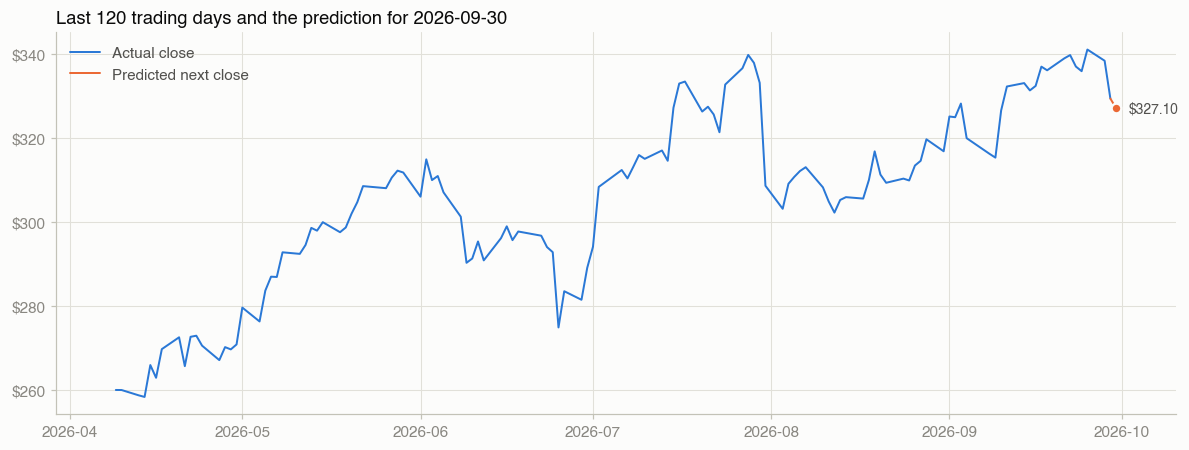

In [7]:
plotting.plot_recent_with_prediction(df, prediction, days=120)
plt.show()

## Simulating daily use
In production the job runs every day after the close, using only data available up to that day. Here we replay the last 20 trading days: for each day we cut the data at that date, predict, and compare with what really happened next.

In [8]:
rows = []
for as_of in df.index[-21:-1]:
    history = df.loc[:as_of]                                   # only data known on that day
    p = predict_next_day(artifacts, history)
    actual_next = df["Close"].iloc[df.index.get_loc(as_of) + 1]
    rows.append({"as of": as_of.date(), "last close": p["last_close"], "predicted next": p["predicted_close"],
                 "actual next": actual_next, "error ($)": p["predicted_close"] - actual_next})
simulation = pd.DataFrame(rows).set_index("as of")
print(f"MAE over these {len(simulation)} days: ${simulation['error ($)'].abs().mean():.2f}")
simulation.round(2)

MAE over these 20 days: $4.37


,last close,predicted next,actual next,error ($)
as of,,,,
2026-08-31,316.85,314.76,325.13,-10.37
2026-09-01,325.13,322.97,324.96,-1.99
2026-09-02,324.96,322.78,328.21,-5.43
2026-09-03,328.21,326.00,319.97,6.03
2026-09-04,319.97,317.82,316.22,1.60
2026-09-08,316.22,314.10,315.34,-1.24
2026-09-09,315.34,313.25,326.57,-13.32
2026-09-10,326.57,324.39,332.27,-7.88
2026-09-11,332.27,330.02,333.08,-3.06



## Operating the model (after deployment)
A deployed model needs care:
- **Data quality checks** on every new file. The loader already validates it and catches swapped columns.
- **Performance monitoring:** log each prediction, then compare it with the actual close the next day. Track a rolling MAE against the naive baseline.
- **Drift monitoring:** watch whether feature distributions (volatility, volume) move far from the training ranges.
- **Retraining:** on a schedule (for example monthly) or when monitored error degrades, retrain with the newest data and redo the evaluation before replacing the model.
- **Versioning:** keep old artifact folders so is possible to roll back.

That closes the CRISP-DM loop: monitoring results feed back into **Business Understanding** for the next iteration.